# Arabic Sentiment Analysis — Baseline Classifier
TF-IDF + Logistic Regression for three-class Arabic sentiment classification using the ArSAS dataset.

This notebook covers data preparation, data-quality checks, model training, validation, error analysis, and exporting the model and dataset splits.

## 1. Setup and imports


In [1]:
%pip -q install datasets pandas scikit-learn matplotlib joblib

In [2]:
# Imports and configuration
import re
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay
)

SEED = 42                       # Reproducible split
LABELS = ["Negative", "Neutral", "Positive"]
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
print("Ready!")

Ready!


## 2. Load and understand the original data
I load the ArSAS dataset and inspect its original columns before selecting the text and sentiment labels.

In [3]:
# Download the dataset from Hugging Face
raw_dataset = load_dataset("arbml/ArSAS", split="train")
raw_df = raw_dataset.to_pandas()

print("Original shape:", raw_df.shape)
print("Available columns:", raw_df.columns.tolist())
display(raw_df[["Tweet_text", "label"]].head())

README.md:   0%|          | 0.00/729 [00:00<?, ?B/s]

data/train-00000-of-00001-34595f80773a1f(…): reconstructing file:   0%|          |  0.00B / 3.00MB            

data/train-00000-of-00001-34595f80773a1f(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/19897 [00:00<?, ? examples/s]

Original shape: (19897, 7)
Available columns: ['#Tweet_ID', 'Tweet_text', 'Topic', 'Sentiment_label_confidence', 'Speech_act_label', 'Speech_act_label_confidence', 'label']


,Tweet_text,label
0,المباراة القـادمة #غانا x #مصر الجولة الأخيرة ...,2
1,هل هذه هي سياسة خارجيه لدوله تحترم نفسها والآخ...,0
2,وزير خارجية فرنسا عن منتدى شباب العالم: شعرت ب...,2
3,ومع السيسي و بشار و ايران و بن زايد و والا خلي...,0
4,أهداف مباراة غانا 0 مصر 1 تصفيات كأس العالم 20...,1


In [4]:
# Map the numerical labels to readable class names
label_map = {0: "Negative", 1: "Neutral", 2: "Positive", 3: "Mixed"}

# Retain tweet IDs when available, for tracing suspicious rows
columns = [col for col in ["#Tweet_ID", "Tweet_text", "label"] if col in raw_df.columns]
df = raw_df[columns].copy()
df = df.rename(columns={"Tweet_text": "text", "#Tweet_ID": "tweet_id"})
df["sentiment"] = df["label"].map(label_map)

print(df["sentiment"].value_counts(dropna=False))
display(df.head())

sentiment
Negative    7384
Neutral     6894
Positive    4400
Mixed       1219
Name: count, dtype: int64


,tweet_id,text,label,sentiment
0,929241870508724224,المباراة القـادمة #غانا x #مصر الجولة الأخيرة ...,2,Positive
1,928942264583376897,هل هذه هي سياسة خارجيه لدوله تحترم نفسها والآخ...,0,Negative
2,928615163250520065,وزير خارجية فرنسا عن منتدى شباب العالم: شعرت ب...,2,Positive
3,931614713368186880,ومع السيسي و بشار و ايران و بن زايد و والا خلي...,0,Negative
4,929755693011427331,أهداف مباراة غانا 0 مصر 1 تصفيات كأس العالم 20...,1,Neutral


## 3. Initial cleaning and basic exploration
I keep Negative, Neutral, and Positive examples. I remove empty and duplicate texts, links, mentions, and extra whitespace, while retaining potentially meaningful Arabic expressions, punctuation, hashtags, and emojis.

In [5]:
def clean_arabic(text):
    """Basic, deliberately conservative social-media cleaning."""
    text = str(text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)   # URLs
    text = re.sub(r"@\w+", " ", text)                   # mentions
    text = re.sub(r"\s+", " ", text)                    # extra whitespace
    return text.strip()

# Keep only the three target sentiment classes
df = df[df["sentiment"].isin(LABELS)].copy()
df = df.dropna(subset=["text", "sentiment"])
df["text"] = df["text"].apply(clean_arabic)
df = df[df["text"].str.len() > 0]
df = df.drop_duplicates(subset=["text"]).reset_index(drop=True)

print("Rows after initial cleaning:", len(df))
print(df["sentiment"].value_counts())
display(df[["text", "sentiment"]].head())

Rows after initial cleaning: 18511
sentiment
Negative    7326
Neutral     6817
Positive    4368
Name: count, dtype: int64


,text,sentiment
0,المباراة القـادمة #غانا x #مصر الجولة الأخيرة ...,Positive
1,هل هذه هي سياسة خارجيه لدوله تحترم نفسها والآخ...,Negative
2,وزير خارجية فرنسا عن منتدى شباب العالم: شعرت ب...,Positive
3,ومع السيسي و بشار و ايران و بن زايد و والا خلي...,Negative
4,أهداف مباراة غانا 0 مصر 1 تصفيات كأس العالم 20...,Neutral


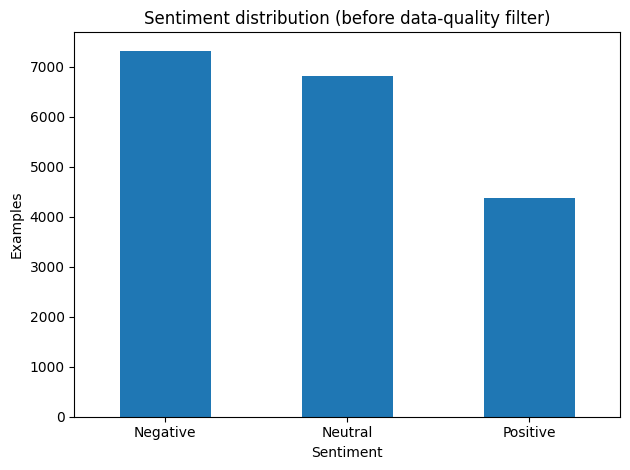

In [6]:
# Examine class imbalance
ax = df["sentiment"].value_counts().reindex(LABELS).plot(kind="bar")
ax.set(title="Sentiment distribution (before data-quality filter)", xlabel="Sentiment", ylabel="Examples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Data Quality Audit
I identified some records containing concatenated tweets and annotation metadata. I flag records matching annotation-like sequences or embedded tweet IDs, then inspect examples before excluding them. This pattern-based check may not identify every malformed record.

In [7]:
# Count annotation terms seen in suspicious text
for term in ["Long_Standing", "Expression", "Assertion"]:
    count = df["text"].str.contains(term, case=False, regex=False, na=False).sum()
    print(f"{term}: {count}")

# Flag annotation-like sequences: category + sentiment + numeric confidence..
# This is more specific than matching the word "Expression" alone.
metadata_pattern = (
    r"\b(?:Long_Standing|Entity|Event|Miscellaneous)\s+"
    r"(?:Negative|Neutral|Positive|Mixed)\s+"
    r"(?:0(?:\.\d+)?|1(?:\.0+)?)\b"
)

# Flag long tweet IDs embedded in the text.
# Tweet IDs belong in a separate field, not within the sentence.
embedded_id_pattern = r"(?<!\d)\d{17,20}(?!\d)"

annotation_mask = df["text"].str.contains(metadata_pattern, case=False, regex=True, na=False)
id_mask = df["text"].str.contains(embedded_id_pattern, regex=True, na=False)
suspicious_mask = annotation_mask | id_mask

print("Rows with annotation-like sequences:", annotation_mask.sum())
print("Rows with embedded 17–20-digit IDs:", id_mask.sum())
print("Total unique flagged rows:", suspicious_mask.sum())

# Inspect a sample of flagged rows
display(df.loc[suspicious_mask, ["text", "sentiment"]].head(3))

Long_Standing: 59
Expression: 66
Assertion: 65
Rows with annotation-like sequences: 70
Rows with embedded 17–20-digit IDs: 70
Total unique flagged rows: 70


,text,sentiment
16,ههههه الخرائط تثبت ان تيران و صنافير سعودية 😂😂...,Neutral
585,#محمد_صلاح We may have many others Entity Posi...,Positive
682,قبل سنة ممكن كنت اتابع نيزك واظن انه من الاكفا...,Positive


## 5. Cleaned Dataset (Version 2)
I create `df_v2` by excluding flagged records and keep the original initially cleaned `df` unchanged. Excluded records are saved for audit purposes. This is not a fully manually verified dataset.

In [8]:
df_v2 = df.loc[~suspicious_mask].copy().reset_index(drop=True)

print("Before quality filter:", len(df))
print("Excluded:", int(suspicious_mask.sum()))
print("After quality filter:", len(df_v2))
print("Class distribution:")
print(df_v2["sentiment"].value_counts())

df.loc[suspicious_mask].to_csv(OUTPUT_DIR / "excluded_suspicious_rows.csv", index=False, encoding="utf-8-sig")

Before quality filter: 18511
Excluded: 70
After quality filter: 18441
Class distribution:
sentiment
Negative    7307
Neutral     6789
Positive    4345
Name: count, dtype: int64


## 6. Train, Validation, and Test Splits
I split the cleaned dataset into 80% training, 10% validation, and 10% testing, with stratification by sentiment label. The exact CSV splits are saved for reuse in the MARBERT experiment.

In [9]:
# First separate 80% train from 20% temporary
train_df, temp_df = train_test_split(
    df_v2[["text", "sentiment"]], test_size=0.20,
    random_state=SEED, stratify=df_v2["sentiment"]
)

# Split remaining 20% equally: 10% validation and 10% test
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED,
    stratify=temp_df["sentiment"]
)

# Reset indices
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Verify there is no exact text overlap across splits.
assert not (set(train_df.text) & set(val_df.text))
assert not (set(train_df.text) & set(test_df.text))
assert not (set(val_df.text) & set(test_df.text))

for name, frame in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    frame.to_csv(OUTPUT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")
    print(f"{name}: {len(frame):,} rows")

X_train, y_train = train_df["text"], train_df["sentiment"]
X_val, y_val = val_df["text"], val_df["sentiment"]
X_test, y_test = test_df["text"], test_df["sentiment"]

train: 14,752 rows
validation: 1,844 rows
test: 1,845 rows


## 7. Baseline Model — TF-IDF + Logistic Regression
I use TF-IDF word and bigram features with a Logistic Regression classifier. The pipeline is fitted only on the training data.

In [10]:
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),    # individual words and adjacent word pairs
        max_features=30000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",  # accounts for uneven class sizes
        random_state=SEED
    ))
])

baseline.fit(X_train, y_train)
print("Baseline training complete!")

Baseline training complete!


## 8. Validation Results
I report validation accuracy, macro-F1, per-class metrics, and a confusion matrix.

Version 2 validation accuracy: 77.82%
Version 2 validation macro-F1: 0.7628
              precision    recall  f1-score   support

    Negative       0.80      0.86      0.83       731
     Neutral       0.80      0.77      0.79       679
    Positive       0.70      0.65      0.67       434

    accuracy                           0.78      1844
   macro avg       0.77      0.76      0.76      1844
weighted avg       0.78      0.78      0.78      1844



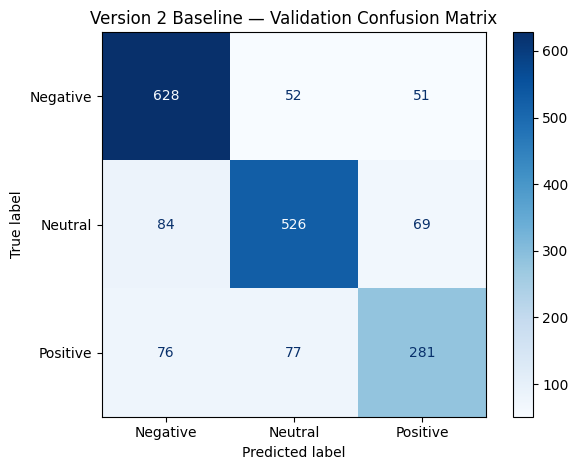

In [11]:
val_predictions = baseline.predict(X_val)
val_accuracy = accuracy_score(y_val, val_predictions)
val_macro_f1 = f1_score(y_val, val_predictions, average="macro")

print(f"Version 2 validation accuracy: {val_accuracy:.2%}")
print(f"Version 2 validation macro-F1: {val_macro_f1:.4f}")
print(classification_report(y_val, val_predictions, labels=LABELS, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_val, val_predictions, labels=LABELS, cmap="Blues", values_format="d"
)
plt.title("Version 2 Baseline — Validation Confusion Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "validation_confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Error Analysis and Example Predictions
I inspect misclassified validation examples and test a few Arabic sentences. The manually chosen examples illustrate behavior; they do not replace held-out evaluation.

In [12]:
val_results = pd.DataFrame({
    "text": X_val.to_numpy(),
    "actual": y_val.to_numpy(),
    "predicted": val_predictions
})

mistakes = val_results[val_results["actual"] != val_results["predicted"]]
positive_mistakes = mistakes[mistakes["actual"] == "Positive"]

print("All validation mistakes:", len(mistakes))
print("Incorrectly classified positive examples:", len(positive_mistakes))
print("Those positive examples were predicted as:")
print(positive_mistakes["predicted"].value_counts())

# Show the full text, not a truncated DataFrame preview
for _, row in positive_mistakes.head(5).iterrows():
    print("\nText:", row["text"])
    print("Expected:", row["actual"], "| Predicted:", row["predicted"])
    print("-" * 50)

All validation mistakes: 409
Incorrectly classified positive examples: 153
Those positive examples were predicted as:
predicted
Neutral     77
Negative    76
Name: count, dtype: int64

Text: #السودان_اكتوبر21🔴أول ثورة شعبية تسقط نظاما عسكريا بصورة سلمية وأصبحت الثورة الأمّ لثورات الربيع العربي التي انفجرت بعد ما يقارب نصف القرن✔
Expected: Positive | Predicted: Negative
--------------------------------------------------

Text: #تيران_وصنافير_مصريه الحريه لماهينور والمدافعين عن الارض ننتظر الحكم بقضيه وقفه ميامى
Expected: Positive | Predicted: Negative
--------------------------------------------------

Text: #الربيع_العربي الحقيقي مايقوم به #محمد_بن_سلمان في المنطقة وفي داخل المملكة بتنظيفه للفساد الداخلي و #الارهاب الخارجي.. وشتان ما بين الربيع السعودي وربيع باقي الدول العربية. رياضياً #تركي_ال_الشيخ يحارب #الفساد خصوصاً عندما ينطلق وسم ك #حيوحشنا_كأس_العالم الذي اطلقه الفسدة
Expected: Positive | Predicted: Negative
--------------------------------------------------

Text: قبل أزمة قطر

In [13]:
# Qualitative checks on Arabic sentences
def predict_sentiment(text):
    return baseline.predict([clean_arabic(text)])[0]

examples = [
    "التطبيق ممتاز وسهل الاستخدام",
    "الخدمة سيئة جدا وما عجبتني",
    "تم تحديث التطبيق اليوم",
    "الصراحة التجربة كانت رهيبة",
    "الخدمة مو ممتازة"
]

for sentence in examples:
    print(f"{sentence}  ->  {predict_sentiment(sentence)}")

التطبيق ممتاز وسهل الاستخدام  ->  Neutral
الخدمة سيئة جدا وما عجبتني  ->  Positive
تم تحديث التطبيق اليوم  ->  Neutral
الصراحة التجربة كانت رهيبة  ->  Negative
الخدمة مو ممتازة  ->  Negative


## 10. Save the Model and Results
I save the trained baseline pipeline and validation metrics. The dataset splits were saved in Section 6.

In [14]:
joblib.dump(baseline, OUTPUT_DIR / "arabic_sentiment_baseline_v2.joblib")

# Save validation metrics
pd.DataFrame([{
    "model": "TF-IDF + Logistic Regression",
    "dataset_version": "v2",
    "evaluation_split": "validation",
    "accuracy": val_accuracy,
    "macro_f1": val_macro_f1
}]).to_csv(OUTPUT_DIR / "validation_metrics.csv", index=False)

print("Saved files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(" -", path)

Saved files:
 - outputs/arabic_sentiment_baseline_v2.joblib
 - outputs/excluded_suspicious_rows.csv
 - outputs/test.csv
 - outputs/train.csv
 - outputs/validation.csv
 - outputs/validation_confusion_matrix.png
 - outputs/validation_metrics.csv


## 11. Final Baseline Test Evaluation
I evaluated the finalized TF-IDF and Logistic Regression baseline on the held-out test set to compare its performance with MARBERT using identical test examples.

The baseline achieved 77.02% accuracy and a macro-F1 score of 0.7541, compared with MARBERT's 83.58% accuracy and 0.8248 macro-F1.

In [17]:

test_predictions = baseline.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, test_predictions):.2%}")
print(f"Test macro-F1: {f1_score(y_test, test_predictions, average='macro'):.4f}")
print(classification_report(y_test, test_predictions, labels=LABELS, zero_division=0))

Test accuracy: 77.02%
Test macro-F1: 0.7541
              precision    recall  f1-score   support

    Negative       0.79      0.86      0.82       731
     Neutral       0.81      0.75      0.78       679
    Positive       0.67      0.64      0.66       435

    accuracy                           0.77      1845
   macro avg       0.76      0.75      0.75      1845
weighted avg       0.77      0.77      0.77      1845



## 12. Export Artifacts
Create a ZIP archive containing the baseline model, dataset splits, validation metrics, confusion matrix, and excluded-record audit.

In [16]:
# Package outputs for download
import shutil
shutil.make_archive("arabic_sentiment_outputs", "zip", OUTPUT_DIR)

try:
    from google.colab import files
    files.download("arabic_sentiment_outputs.zip")
except ImportError:
    print("Not running in Colab; the ZIP was saved locally.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>